---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 25 (IMKSIAI)

- Yusuf Faishal Listyardi (13524014)
- Aziza Dharma Putri (13524017)
- Niko Samuel Simanjuntak (13524029)
- An-Dafa Anza Alvansyah (13524038)
- Kalyca Nathania Benedicta M. (13524071)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pesanan meninggalkan kamar kosong yang sebenarnya bisa dijual ke tamu lain. Prediksi pembatalan sejak awal membantu penginapan merencanakan *overbooking*, mengirim pengingat, dan menyusun kebijakan pembatalan.

## Aim

Membangun model klasifikasi *from scratch* yang memprediksi apakah sebuah pesanan dibatalkan (`is_canceled = 1`) atau tidak (`is_canceled = 0`).

## Metric

Leaderboard Kaggle memakai **Macro F1-score**, yaitu rata-rata F1 kelas batal dan F1 kelas tidak batal. Kedua kelas berbobot sama, sehingga model yang hanya menebak kelas mayoritas mendapat skor rendah. Seluruh validasi di notebook ini memakai metrik yang sama (`macro_f1` di `src/metrics.py`).

## Dataset

`train.csv` berisi 27.373 pesanan beserta label, `test.csv` berisi 6.844 pesanan tanpa label. Ada 17 fitur: jumlah tamu, lama menginap, paket makan, kategori kamar, jarak hari pemesanan ke kedatangan, tanggal kedatangan, kanal pemesanan, riwayat tamu, harga per malam (IDR), dan jumlah permintaan khusus. Delapan kolom memiliki *missing values*.

## Approach

1. Pisahkan `train.csv` menjadi data latih dan validasi sebelum *preprocessing*.
2. Pelajari semua statistik *preprocessing* dari data latih saja, lalu terapkan ke validasi dan test.
3. Latih model *from scratch* (`src/`), pilih *hyperparameter* dengan *stratified 5-fold cross-validation*.
4. Bandingkan dengan `scikit-learn`, simpan model, dan buat submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modul from scratch ada di folder src/.
ROOT = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from preprocessing import Preprocessor, drop_duplicate_rows, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from knn import KNN
from metrics import macro_f1, accuracy, confusion_matrix, f1_per_class, stratified_kfold_indices

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    MODEL_DIR  = ROOT / 'output' / 'models'
    VAL_SIZE   = 0.2
    N_FOLDS    = 5
    PLOT_COLOR = 'steelblue'
    # Bobot fitur untuk jarak KNN; asal nilainya dijelaskan di bagian Improvements.
    # Key-nya adalah nama kolom di Preprocessor.
    FEATURE_WEIGHTS = {
        'log_lead_time': 1.5, 'days_before_arrival': 1.5,
        'special_requests': 1.5, 'nightly_rate_idr': 1.5,
        'meal_package': 0.5, 'room_category': 0.5,
    }

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
print(train_df.dtypes.to_string())
train_df.describe().T

id                           object
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                 object
needs_parking               float64
room_category                object
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel              object
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


**Insights:**

- `id` dibaca sebagai teks dan tidak dipakai sebagai fitur.
- Fitur kategorikal nominal: `meal_package`, `room_category` (huruf tanpa urutan), `booking_channel`.
- Fitur biner: `needs_parking`, `is_returning_guest`. Sisanya numerik.
- `days_before_arrival` dan `nightly_rate_idr` memiliki rentang yang jauh lebih besar daripada fitur lain, sehingga model berbasis jarak memerlukan *scaling*.

## Explore Data

This part covers distributions and relationships between attributes.

Proporsi target:
is_canceled
0    0.672
1    0.328


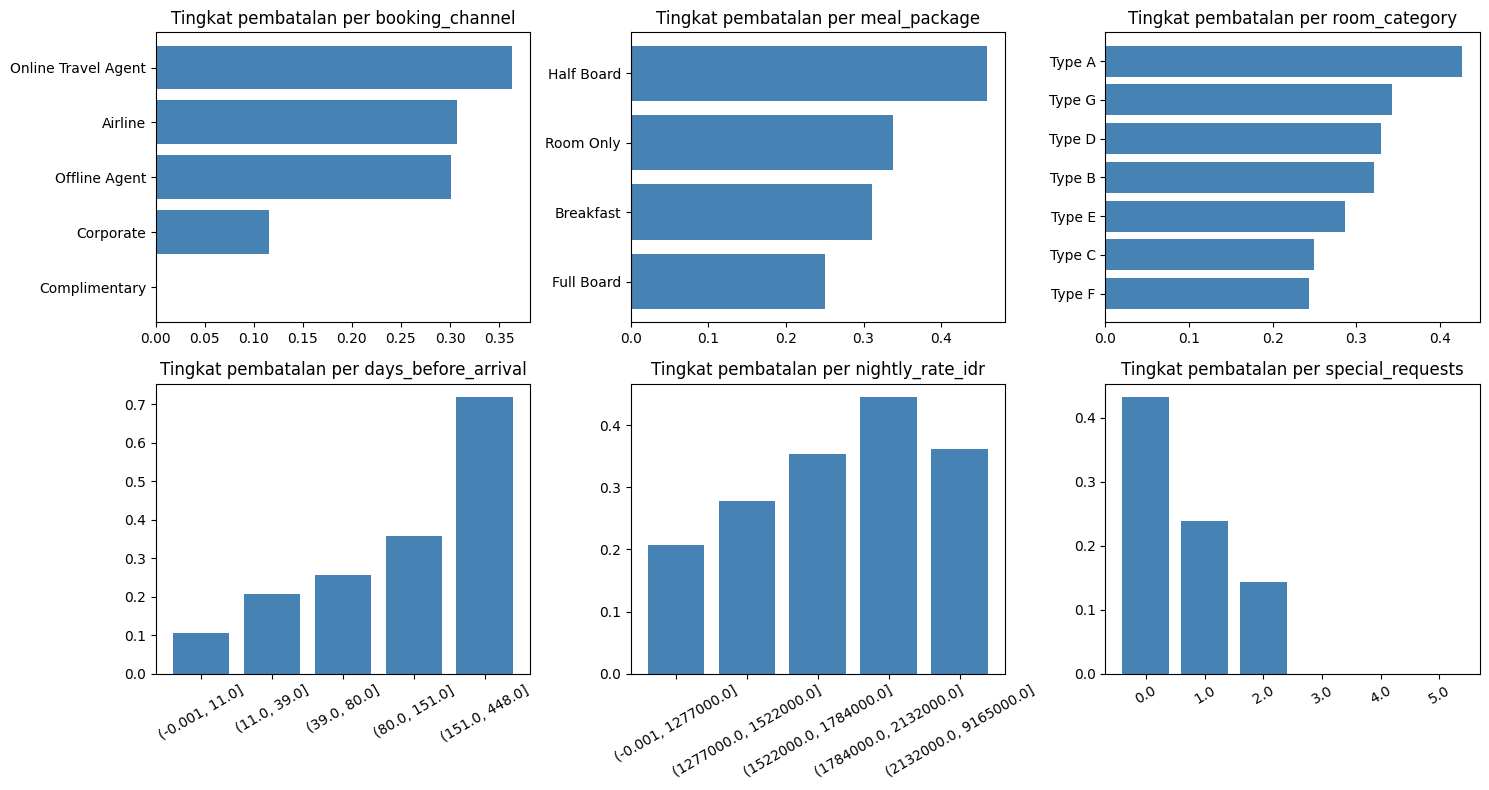

In [7]:
print('Proporsi target:')
print(train_df[TARGET].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes[0], ['booking_channel', 'meal_package', 'room_category']):
    rate = train_df.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
for ax, col in zip(axes[1], ['days_before_arrival', 'nightly_rate_idr', 'special_requests']):
    if train_df[col].nunique() > 10:
        bins = pd.qcut(train_df[col], 5, duplicates='drop')
    else:
        bins = train_df[col]
    rate = train_df.groupby(bins, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Insights:**

- Kelas tidak seimbang secara moderat: sekitar 67% tidak batal, 33% batal.
- `days_before_arrival` adalah sinyal terkuat: pesanan yang dibuat jauh hari lebih sering dibatalkan.
- `special_requests` berbanding terbalik dengan pembatalan; tamu dengan 3 permintaan atau lebih hampir tidak pernah membatalkan.
- Kanal *Complimentary* dan *Corporate* jarang batal, sedangkan *Online Travel Agent* paling sering.
- Pola-pola ini tidak linear, sehingga model seperti KNN dan *decision tree* diperkirakan lebih cocok daripada model linear.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
quality = pd.DataFrame({
    'missing_train': train_df.isna().sum(),
    'missing_test': test_df.isna().sum(),
})
print(quality[quality.sum(axis=1) > 0])

feature_cols = [c for c in train_df.columns if c != 'id']
print('\nBaris duplikat (tanpa id):', train_df.duplicated(subset=feature_cols).sum())
print('Harga 0 (komplimenter):', (train_df['nightly_rate_idr'] == 0).sum())
print('0 orang dewasa:', (train_df['num_adults'] == 0).sum())
print('0 malam menginap:', ((train_df['weekend_nights'] + train_df['weekday_nights']) == 0).sum())
dates = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day), errors='coerce')
print('Tanggal tidak valid:', dates.isna().sum())

                     missing_train  missing_test
days_before_arrival           1123         290.0
meal_package                  1760         442.0
needs_parking                 1082         247.0
nightly_rate_idr              2038         540.0
num_adults                     809         180.0
num_children                  3035         747.0
room_category                 1002         242.0
special_requests              2500         593.0

Baris duplikat (tanpa id): 64
Harga 0 (komplimenter): 413
0 orang dewasa: 106
0 malam menginap: 64
Tanggal tidak valid: 0


**Insights:**

- Delapan kolom memiliki *missing values* sebesar 3–11%, dengan pola serupa di train dan test.
- Terdapat 64 baris duplikat. Duplikat hanya dibuang dari data latih agar validasi tetap mencerminkan data asli.
- Harga 0 sesuai deskripsi dataset (menginap komplimenter), jadi bukan kesalahan data.
- Pesanan dengan 0 orang dewasa atau 0 malam jumlahnya sedikit dan juga muncul di data test, sehingga tetap dipertahankan.
- Semua tanggal kedatangan valid.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
from sklearn.model_selection import train_test_split

train_set, val_set = train_test_split(
    train_df, test_size=CFG.VAL_SIZE, stratify=train_df[TARGET], random_state=CFG.SEED,
)
train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)
print(f'Train: {train_set.shape}  Validation: {val_set.shape}')
print('Proporsi batal  train: %.3f  val: %.3f' % (train_set[TARGET].mean(), val_set[TARGET].mean()))

Train: (21898, 19)  Validation: (5475, 19)
Proporsi batal  train: 0.328  val: 0.328


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
# id hanya penanda baris, sedangkan target dipisahkan saat format data.
selected_features = NUMERIC_COLS + CATEGORICAL_COLS
print(len(selected_features), 'fitur dipakai:', selected_features)

17 fitur dipakai: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category', 'booking_channel']


**Insights:**

Semua 17 fitur asli dipakai. Pada eksperimen awal, membuang fitur mana pun tidak menaikkan Macro F1, sedangkan semua fitur memiliki hubungan yang masuk akal dengan pembatalan.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
print(train_set[selected_features].isna().sum()[lambda s: s > 0])
print('\nMedian (dari data latih) untuk imputasi numerik:')
print(train_set[NUMERIC_COLS].median().to_string())

num_adults              636
num_children           2426
needs_parking           885
days_before_arrival     877
nightly_rate_idr       1622
special_requests       2015
meal_package           1403
room_category           810
dtype: int64

Median (dari data latih) untuk imputasi numerik:
num_adults                        2.0
num_children                      0.0
weekend_nights                    1.0
weekday_nights                    2.0
needs_parking                     0.0
days_before_arrival              57.0
arrival_year                   2024.0
arrival_month                     8.0
arrival_day                      16.0
is_returning_guest                0.0
prior_cancellations               0.0
prior_completed_bookings          0.0
nightly_rate_idr            1647000.0
special_requests                  0.0


**Insights:**

- Numerik: diisi median data latih, karena median tahan terhadap distribusi yang miring seperti `days_before_arrival`.
- Kategorikal: diisi kategori baru `Unknown`, sehingga informasi "tidak diisi" tetap ada.
- Imputasi dikerjakan di dalam `Preprocessor.fit` / `transform` (`src/preprocessing.py`) agar median hanya dihitung dari data latih.

### Duplicates

This part covers repeated records.

In [12]:
n_before = len(train_set)
train_set = drop_duplicate_rows(train_set)
print(f'Duplikat dibuang dari data latih: {n_before - len(train_set)}')

Duplikat dibuang dari data latih: 40


### Outliers

This part covers values far from the rest of the data.

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(train_set[NUMERIC_COLS].apply(iqr_outliers).sort_values(ascending=False).head(8))

num_adults                  5916
arrival_year                3941
num_children                1613
nightly_rate_idr             886
days_before_arrival          750
needs_parking                644
is_returning_guest           545
prior_completed_bookings     477
dtype: int64


**Insights:**

- Pada kolom diskret dengan IQR = 0 (`num_adults`, `arrival_year`, `num_children`, kolom biner), aturan IQR menandai hampir semua nilai selain modus sebagai *outlier*. Aturan ini tidak cocok untuk kolom seperti itu.
- Pada kolom kontinu (`nightly_rate_idr`, `days_before_arrival`, `prior_completed_bookings`), nilai di luar batas IQR adalah nilai yang mungkin terjadi, bukan kesalahan input.
- Karena itu *outlier* dipertahankan. Efeknya pada jarak KNN dikurangi oleh standarisasi dan transformasi log pada lead time.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
# Kolom bilangan bulat yang memiliki NaN terbaca sebagai float. Ini tidak masalah karena semua fitur numerik diproses sebagai float.
for col in CATEGORICAL_COLS:
    print(col, sorted(train_set[col].dropna().unique()))

meal_package ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
room_category ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
booking_channel ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


**Insights:**

Label kategori konsisten dan tidak ada nilai yang mustahil. Kategori yang sangat jarang (misalnya *Full Board* dengan 4 baris) digabung menjadi `Other` saat *encoding*.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [15]:
pp_demo = Preprocessor().fit(train_set)
derived_preview = Preprocessor._derive(train_set[NUMERIC_COLS].fillna(pp_demo.medians_))
derived_preview.head()

,log_lead_time,arrival_date_ordinal
0,5.963579,739181.0
1,5.726848,739193.0
2,5.117994,738795.0
3,3.401197,739221.0
4,3.332205,739015.0


**Insights:**

- `log_lead_time = log(1 + days_before_arrival)`: lead time sangat miring ke kanan; log membuat jarak antara 0 dan 30 hari lebih berarti daripada jarak antara 300 dan 330 hari.
- `arrival_date_ordinal`: tanggal kedatangan sebagai satu angka, sehingga tren waktu (tingkat batal 2023 jauh lebih rendah daripada 2024) terwakili dalam satu dimensi.
- Kedua fitur ini menaikkan Macro F1 KNN pada *cross-validation*. Fitur turunan lain yang dicoba (total malam, total tamu, harga per tamu, hari dalam minggu) tidak membantu KNN sehingga tidak dipakai.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print('Mean dan std (dari data latih) untuk standarisasi:')
print(pd.DataFrame({'mean': pp_demo.mean_, 'std': pp_demo.std_}).round(3))

Mean dan std (dari data latih) untuk standarisasi:
                                 mean         std
num_adults                      1.852       0.512
num_children                    0.105       0.407
weekend_nights                  0.818       0.875
weekday_nights                  2.198       1.421
needs_parking                   0.029       0.169
days_before_arrival            83.873      84.245
arrival_year                 2023.820       0.384
arrival_month                   7.395       3.077
arrival_day                    15.540       8.772
is_returning_guest              0.025       0.156
prior_cancellations             0.021       0.357
prior_completed_bookings        0.139       1.627
nightly_rate_idr          1713998.445  563908.889
special_requests                0.608       0.786
log_lead_time                   3.741       1.453
arrival_date_ordinal       739029.164     139.961


**Insights:**

Standarisasi z-score dipakai untuk KNN, karena tanpa *scaling* jarak didominasi `nightly_rate_idr` (jutaan) dan `days_before_arrival` (ratusan). Kolom *one-hot* dibiarkan bernilai 0/1.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
for col, cats in pp_demo.categories_.items():
    print(col, '->', cats)

meal_package -> ['Breakfast', 'Half Board', 'Room Only', 'Unknown', 'Other']
room_category -> ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'Unknown', 'Other']
booking_channel -> ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent', 'Other']


**Insights:**

Ketiga fitur kategorikal bersifat nominal (tidak berurutan), jadi dipakai *one-hot encoding*. *Label encoding* akan membuat KNN menganggap, misalnya, Type A lebih dekat ke Type B daripada ke Type G, padahal huruf tersebut tidak memiliki urutan.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
X_demo = pp_demo.transform(train_set)
Xc = X_demo - X_demo.mean(axis=0)
explained = np.linalg.svd(Xc, compute_uv=False) ** 2
explained_ratio = np.cumsum(explained) / explained.sum()
for n in (5, 10, 15, 20):
    print(f'{n} komponen utama menjelaskan {explained_ratio[n - 1]:.1%} variansi')

5 komponen utama menjelaskan 51.0% variansi
10 komponen utama menjelaskan 78.8% variansi
15 komponen utama menjelaskan 94.3% variansi
20 komponen utama menjelaskan 99.0% variansi


**Insights:**

Dengan hanya 35 kolom setelah *encoding*, dimensi masih kecil untuk KNN. PCA juga membutuhkan banyak komponen untuk mempertahankan sebagian besar variansi, sehingga PCA tidak dipakai pada model utama.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
print(train_set[TARGET].value_counts().to_string())
print(train_set[TARGET].value_counts(normalize=True).round(3).to_string())

is_canceled
0    14696
1     7162
is_canceled
0    0.672
1    0.328


**Insights:**

Rasio sekitar 67:33 tergolong tidak seimbang secara moderat. Tidak dilakukan *resampling*; pada eksperimen awal, model sudah memprediksi kedua kelas dengan baik, dan menggeser *threshold* keputusan tidak menaikkan Macro F1 KNN.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
y_train = train_set[TARGET].to_numpy()
y_val = val_set[TARGET].to_numpy()
print('y_train', y_train.shape, ' y_val', y_val.shape)

y_train (21858,)  y_val (5475,)


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True)
X_train = preprocessor.fit_transform(train_set)   # Fit hanya pada data latih.
X_val = preprocessor.transform(val_set)           # Validasi hanya ditransformasi.

print('X_train', X_train.shape, ' X_val', X_val.shape)
print('NaN tersisa:', np.isnan(X_train).sum(), np.isnan(X_val).sum())
print(preprocessor.feature_names_)

X_train (21858, 35)  X_val (5475, 35)
NaN tersisa: 0 0
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'log_lead_time', 'arrival_date_ordinal', 'meal_package=Breakfast', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'meal_package=Other', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'room_category=Other', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online Travel Agent', 'booking_channel=Other']


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

Implementasi: `src/knn.py` (kelas `KNN`). Jarak Euclidean, Manhattan, atau Minkowski; voting seragam atau berbobot `1/jarak`; komputasi jarak per *batch* agar memori terkendali. Bobot fitur pada jarak diterapkan di `Preprocessor(feature_weights=...)`.

In [22]:
# Tuning hyperparameter dengan stratified 5-fold CV pada data latih.
# Preprocessor di-fit ulang di setiap fold supaya fold validasi tidak bocor.
K_GRID = [5, 11, 15, 21, 31, 41]
P_GRID = [1, 2]   # 1 = Manhattan, 2 = Euclidean
W_GRID = ['uniform', 'distance']
FW_GRID = {'none': None, 'weighted': CFG.FEATURE_WEIGHTS}

cv_scores = {}
start = time.time()
for fold, (tr_idx, va_idx) in enumerate(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED)):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    for fw_name, fw in FW_GRID.items():
        pp = Preprocessor(feature_weights=fw).fit(fold_tr)
        Xf_tr, Xf_va = pp.transform(fold_tr), pp.transform(fold_va)
        for p in P_GRID:
            # Tetangga dicari sekali dengan k terbesar, k yang lebih kecil cukup memotong hasilnya.
            searcher = KNN(k=max(K_GRID), p=p).fit(Xf_tr, y_train[tr_idx])
            dist, idx = searcher.kneighbors(Xf_va)
            for w in W_GRID:
                searcher.weights = w
                for k in K_GRID:
                    pred = searcher.predict_from_neighbors(dist, idx, k)
                    cv_scores.setdefault((fw_name, k, p, w), []).append(macro_f1(y_train[va_idx], pred))
    print(f'fold {fold + 1} selesai ({time.time() - start:.0f} s)')

cv_table = (pd.DataFrame([(fw, k, p, w, np.mean(s), np.std(s), s) for (fw, k, p, w), s in cv_scores.items()],
                         columns=['feature_weights', 'k', 'p', 'weights', 'cv_macro_f1', 'std', 'fold_scores'])
            .sort_values('cv_macro_f1', ascending=False).reset_index(drop=True))
cv_table.drop(columns='fold_scores').head(10)

fold 1 selesai (48 s)
fold 2 selesai (94 s)
fold 3 selesai (142 s)
fold 4 selesai (190 s)
fold 5 selesai (236 s)


,feature_weights,k,p,weights,cv_macro_f1,std
0,weighted,21,1,distance,0.842070,0.003191
1,weighted,11,1,distance,0.840809,0.003037
2,weighted,15,1,distance,0.840287,0.003150
3,weighted,31,1,distance,0.840049,0.003084
4,weighted,41,1,distance,0.839418,0.002277
5,weighted,5,1,distance,0.834106,0.002179
6,none,21,1,distance,0.833814,0.003738
7,none,11,1,distance,0.833604,0.004136
8,none,15,1,distance,0.833575,0.003147
9,none,31,1,distance,0.833208,0.004443


**Insights:**

- Jarak Manhattan (`p=1`) konsisten lebih baik daripada Euclidean. Manhattan tidak mengkuadratkan selisih, sehingga satu fitur yang sangat berbeda tidak mendominasi jarak.
- Pembobotan `distance` lebih baik daripada `uniform` untuk k besar, karena tetangga jauh tidak lagi bersuara sama kuat.
- Jarak berbobot fitur (`weighted`) lebih baik daripada tanpa bobot pada konfigurasi yang sama (lihat perbandingan per fold di bawah).
- k kecil (5) cenderung *overfit* terhadap *noise*, k besar (41) mulai terlalu halus; puncaknya di sekitar k = 21.

In [23]:
best = cv_table.iloc[0]
BEST_FW_NAME, BEST_K, BEST_P, BEST_W = best.feature_weights, int(best.k), int(best.p), best.weights
BEST_FW = FW_GRID[BEST_FW_NAME]
print(f'Hyperparameter terbaik: feature_weights={BEST_FW_NAME}, k={BEST_K}, p={BEST_P}, weights={BEST_W}  (CV macro F1 = {best.cv_macro_f1:.4f})')

# Bandingkan jarak berbobot dan tanpa bobot pada fold yang sama.
def pick(fw):
    q = cv_table.query('feature_weights == @fw and k == @BEST_K and p == @BEST_P and weights == @BEST_W')
    return q.iloc[0]

a, b = np.array(pick('weighted').fold_scores), np.array(pick('none').fold_scores)
print(f'Berbobot vs tanpa bobot (k={BEST_K}, p={BEST_P}, {BEST_W}): selisih rata-rata {np.mean(a - b):+.4f}, '
      f'berbobot menang di {np.sum(a > b)}/{len(a)} fold')


# Preprocessor di-fit ulang dengan bobot terpilih pada seluruh data latih.
preprocessor = Preprocessor(feature_weights=BEST_FW)
X_train = preprocessor.fit_transform(train_set)
X_val = preprocessor.transform(val_set)
knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(X_train, y_train)
start = time.time()
knn_val_pred = knn.predict(X_val)
print(f'Waktu prediksi validasi: {time.time() - start:.1f} s')
print(f'Validation macro F1 = {macro_f1(y_val, knn_val_pred):.4f}   accuracy = {accuracy(y_val, knn_val_pred):.4f}')

Hyperparameter terbaik: feature_weights=weighted, k=21, p=1, weights=distance  (CV macro F1 = 0.8421)
Berbobot vs tanpa bobot (k=21, p=1, distance): selisih rata-rata +0.0083, berbobot menang di 5/5 fold
Waktu prediksi validasi: 33.9 s
Validation macro F1 = 0.8486   accuracy = 0.8687


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [24]:
# Write your code here

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [25]:
# Write your code here

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [26]:
# Write your code here

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [27]:
# Write your code here

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [28]:
results = pd.DataFrame([
    {'model': f'KNN (k={BEST_K}, p={BEST_P}, {BEST_W}, feature weights={BEST_FW_NAME})',
     'val_macro_f1': macro_f1(y_val, knn_val_pred),
     'val_accuracy': accuracy(y_val, knn_val_pred)},
    # DTL, Logistic Regression, SVM, dan Naive Bayes ditambahkan di sini.
])
results

,model,val_macro_f1,val_accuracy
0,"KNN (k=21, p=1, distance, feature weights=weig...",0.848639,0.868676


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

**Asal bobot fitur KNN.** Bobot `CFG.FEATURE_WEIGHTS` dicari dengan *coordinate search* (setiap kelompok fitur dikali 0,5 / 0,75 / 1,5 / 2, perubahan diterima hanya jika Macro F1 CV naik > 0,0005) pada lipatan CV dengan *seed* terpisah, lalu diverifikasi pada lipatan baru yang tidak dipakai untuk memilih dan pada data validasi. Rincian proses pencariannya dibahas di laporan.

Alasan bobot: `days_before_arrival`, `special_requests`, dan `nightly_rate_idr` adalah prediktor terkuat sehingga diberi bobot lebih besar. Sebaliknya, `meal_package` dan `room_category` lemah, padahal satu perbedaan kategori menambah jarak Manhattan sebesar 2 (dua kolom *one-hot* berbeda), lebih besar daripada selisih 1 standar deviasi pada fitur numerik. Bobotnya diperkecil agar tidak menambah *noise* pada jarak.

Sel di bawah memeriksa apakah bobot ini terlalu "pas" dengan data (*overfitting* terhadap nilai bobot): setiap bobot digeser acak ±25%, lalu Macro F1 validasi dibandingkan.

In [29]:
rng = np.random.default_rng(CFG.SEED)
robust_rows = []
for i in range(3):
    perturbed = {c: w * rng.uniform(0.75, 1.25) for c, w in CFG.FEATURE_WEIGHTS.items()}
    pp = Preprocessor(feature_weights=perturbed).fit(train_set)
    pred = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(pp.transform(train_set), y_train).predict(pp.transform(val_set))
    robust_rows.append({'percobaan': i + 1, 'val_macro_f1': macro_f1(y_val, pred),
                        **{c: round(w, 2) for c, w in perturbed.items()}})
robust = pd.DataFrame(robust_rows)
print(f'Bobot asli: val macro F1 = {macro_f1(y_val, knn_val_pred):.4f}')
robust

Bobot asli: val macro F1 = 0.8486


,percobaan,val_macro_f1,log_lead_time,days_before_arrival,special_requests,nightly_rate_idr,meal_package,room_category
0,1,0.849294,1.71,1.45,1.77,1.65,0.40,0.62
1,2,0.847563,1.70,1.71,1.22,1.46,0.47,0.61
2,3,0.847984,1.61,1.74,1.46,1.30,0.51,0.39


**Insights:**

Skor validasi hampir tidak berubah ketika bobot digeser ±25%. Artinya performa tidak bergantung pada nilai bobot yang sangat spesifik, sehingga kenaikan dari pembobotan bukan hasil *overfitting* terhadap data validasi.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

          from scratch  scikit-learn
macro F1        0.8486        0.8486
accuracy        0.8687        0.8687
Prediksi identik: 100.00%


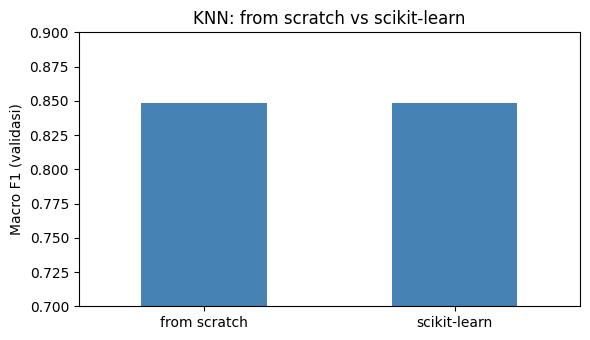

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

sk_knn = KNeighborsClassifier(n_neighbors=BEST_K, p=BEST_P, weights=BEST_W, algorithm='brute')
sk_knn.fit(X_train, y_train)
sk_val_pred = sk_knn.predict(X_val)

comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, knn_val_pred), accuracy(y_val, knn_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_val_pred, average='macro'), np.mean(sk_val_pred == y_val)],
}, index=['macro F1', 'accuracy'])
print(comparison.round(4))
print(f'Prediksi identik: {np.mean(knn_val_pred == sk_val_pred):.2%}')

fig, ax = plt.subplots(figsize=(6, 3.5))
comparison.loc['macro F1'].plot.bar(ax=ax, color=CFG.PLOT_COLOR)
ax.set_ylim(0.7, 0.9)
ax.set_ylabel('Macro F1 (validasi)')
ax.set_title('KNN: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

Dengan *hyperparameter* dan data yang sama, prediksi KNN *from scratch* identik dengan `KNeighborsClassifier(algorithm='brute')`. Ini menunjukkan perhitungan jarak, pemilihan tetangga, dan voting berbobot sudah benar. Perbedaan utamanya ada pada kecepatan: scikit-learn memakai implementasi C yang lebih cepat.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [31]:
knn_path = CFG.MODEL_DIR / 'knn.pkl'
prep_path = CFG.MODEL_DIR / 'preprocessor.pkl'
knn.save(knn_path)
preprocessor.save(prep_path)

loaded_knn = KNN.load(knn_path)
loaded_prep = Preprocessor.load(prep_path)
reloaded_pred = loaded_knn.predict(loaded_prep.transform(val_set))
print('Prediksi model hasil load sama dengan model asli:', np.array_equal(reloaded_pred, knn_val_pred))

Prediksi model hasil load sama dengan model asli: True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [32]:
# Model akhir: preprocessor dan KNN di-fit ulang pada seluruh train.csv (tanpa duplikat).
full_train = drop_duplicate_rows(train_df)
final_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=BEST_FW).fit(full_train)
final_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W).fit(final_prep.transform(full_train), full_train[TARGET].to_numpy())

test_pred = final_knn.predict(final_prep.transform(test_df))   # Test hanya ditransformasi.
submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': test_pred.astype(int)})

assert len(submission) == len(test_df) and submission['id'].is_unique
assert set(submission['is_canceled'].unique()) <= {0, 1}
submission_path = CFG.OUTPUT_DIR / 'submission_knn.csv'
submission.to_csv(submission_path, index=False)
final_knn.save(CFG.MODEL_DIR / 'knn_final.pkl')
final_prep.save(CFG.MODEL_DIR / 'preprocessor_final.pkl')

print(submission_path, submission.shape)
print('Proporsi prediksi batal di test: %.3f' % submission['is_canceled'].mean())
submission.head()

d:\SEMESTER 5\2. AI\TUBES 2\IF3170_G25_IMKSIAI\output\submission_knn.csv (6844, 2)
Proporsi prediksi batal di test: 0.297


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [33]:
cm = confusion_matrix(y_val, knn_val_pred)
print('Confusion matrix (baris = asli, kolom = prediksi):')
print(pd.DataFrame(cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
print('F1 per kelas:', f1_per_class(y_val, knn_val_pred).round(4))

err = val_set.assign(pred=knn_val_pred, wrong=knn_val_pred != y_val)
lead_bins = pd.cut(err['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print('\nTingkat kesalahan per lead time:')
print(err.groupby(lead_bins, observed=True)['wrong'].agg(['mean', 'size']).round(3))
print('\nTingkat kesalahan per kanal:')
print(err.groupby('booking_channel')['wrong'].agg(['mean', 'size']).round(3))

Confusion matrix (baris = asli, kolom = prediksi):
        pred 0  pred 1
asli 0    3374     307
asli 1     412    1382
F1 per kelas: [0.9037 0.7936]

Tingkat kesalahan per lead time:
                      mean  size
days_before_arrival             
(-1, 7]              0.069   802
(7, 30]              0.113   965
(30, 90]             0.158  1562
(90, 180]            0.181  1133
(180, 500]           0.063   767

Tingkat kesalahan per kanal:
                      mean  size
booking_channel                 
Airline              0.125    16
Complimentary        0.017    58
Corporate            0.068   309
Offline Agent        0.068  1573
Online Travel Agent  0.167  3519


**Insights:**

- F1 kelas tidak batal (sekitar 0,90) jauh lebih tinggi daripada kelas batal (sekitar 0,79). Kelas batal adalah titik lemah yang menurunkan Macro F1.
- Kesalahan paling banyak pada pesanan dengan lead time menengah (30–180 hari, tingkat salah 16–18%), di mana pola batal dan tidak batal paling bercampur. Lead time di bawah 7 hari atau di atas 180 hari jauh lebih mudah ditebak.
- Kanal *Online Travel Agent* memiliki tingkat salah tertinggi (sekitar 17%) dibanding *Offline Agent* atau *Corporate* (sekitar 7%).
- Perbaikan berikutnya: bandingkan dengan DTL (yang menangani interaksi fitur secara eksplisit) dan analisis *cost-sensitive* untuk bonus.